In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

In [4]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"

TRAIN_PATH = RAW_DATA_DIR / "train.csv"
TEST_PATH = RAW_DATA_DIR / "test.csv"

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

train_df.shape, test_df.shape

((699635, 23), (299844, 22))

Info

In [5]:
train_df.shape

(699635, 23)

In [6]:
train_df.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


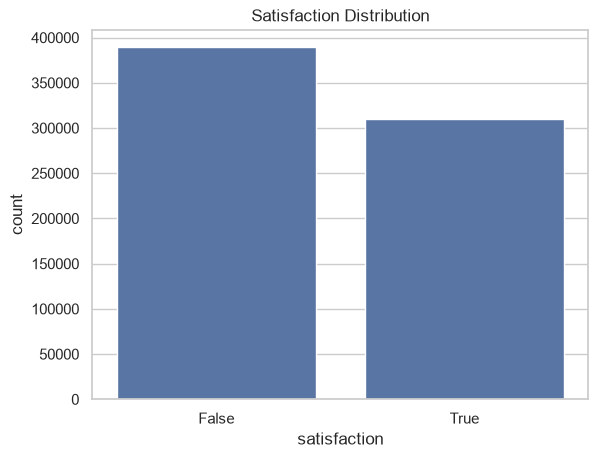

In [36]:
sns.countplot(
    data=train_df,
    x='satisfaction'
)

plt.title('Satisfaction Distribution')
plt.show()

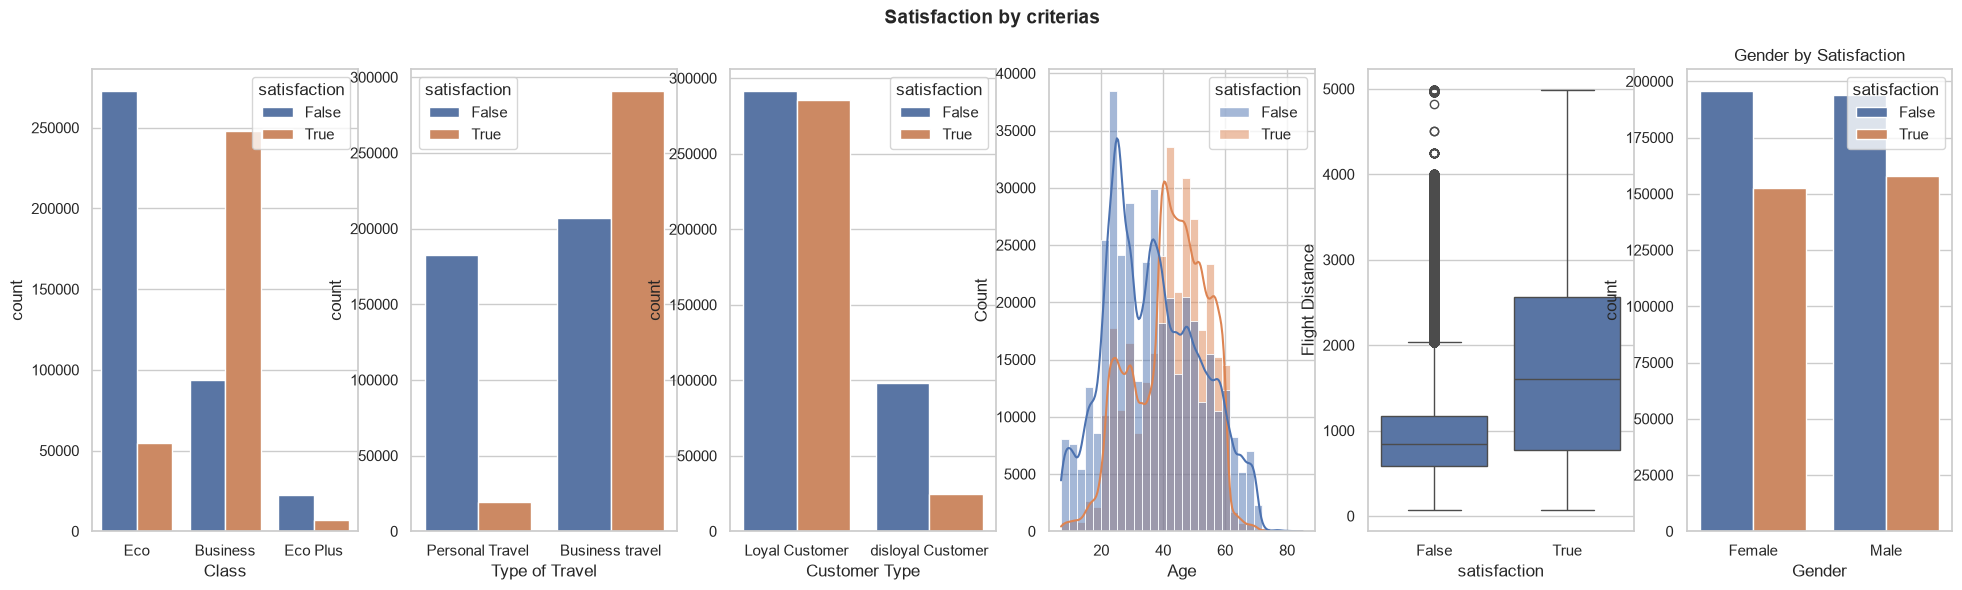

In [21]:
fig, axes = plt.subplots(1, 6, figsize=(24, 6))
fig.suptitle("Satisfaction by criterias", fontsize=14, fontweight="bold")

sns.countplot(
    data=train_df,
    x='Class',
    hue='satisfaction',
    ax=axes[0]
)

plt.title('Satisfaction by Class')

sns.countplot(
    data=train_df,
    x='Type of Travel',
    hue='satisfaction',
    ax=axes[1]
)

plt.title('Satisfaction by Type of Travel')

sns.countplot(
    data=train_df,
    x='Customer Type',
    hue='satisfaction',
    ax=axes[2],
)

plt.title('Satisfaction by Customer Type')

sns.histplot(
    data=train_df,
    x='Age',
    hue='satisfaction',
    bins=30,
    kde=True,
    ax=axes[3]
)

plt.title('Age Distribution by Satisfaction')

sns.boxplot(
    data=train_df,
    x='satisfaction',
    y='Flight Distance',
    ax=axes[4]
)

plt.title('Flight Distance by Satisfaction')

sns.countplot(
    data=train_df,
    x='Gender',
    hue='satisfaction',
    ax=axes[5]
)

plt.title('Gender by Satisfaction')

plt.show()

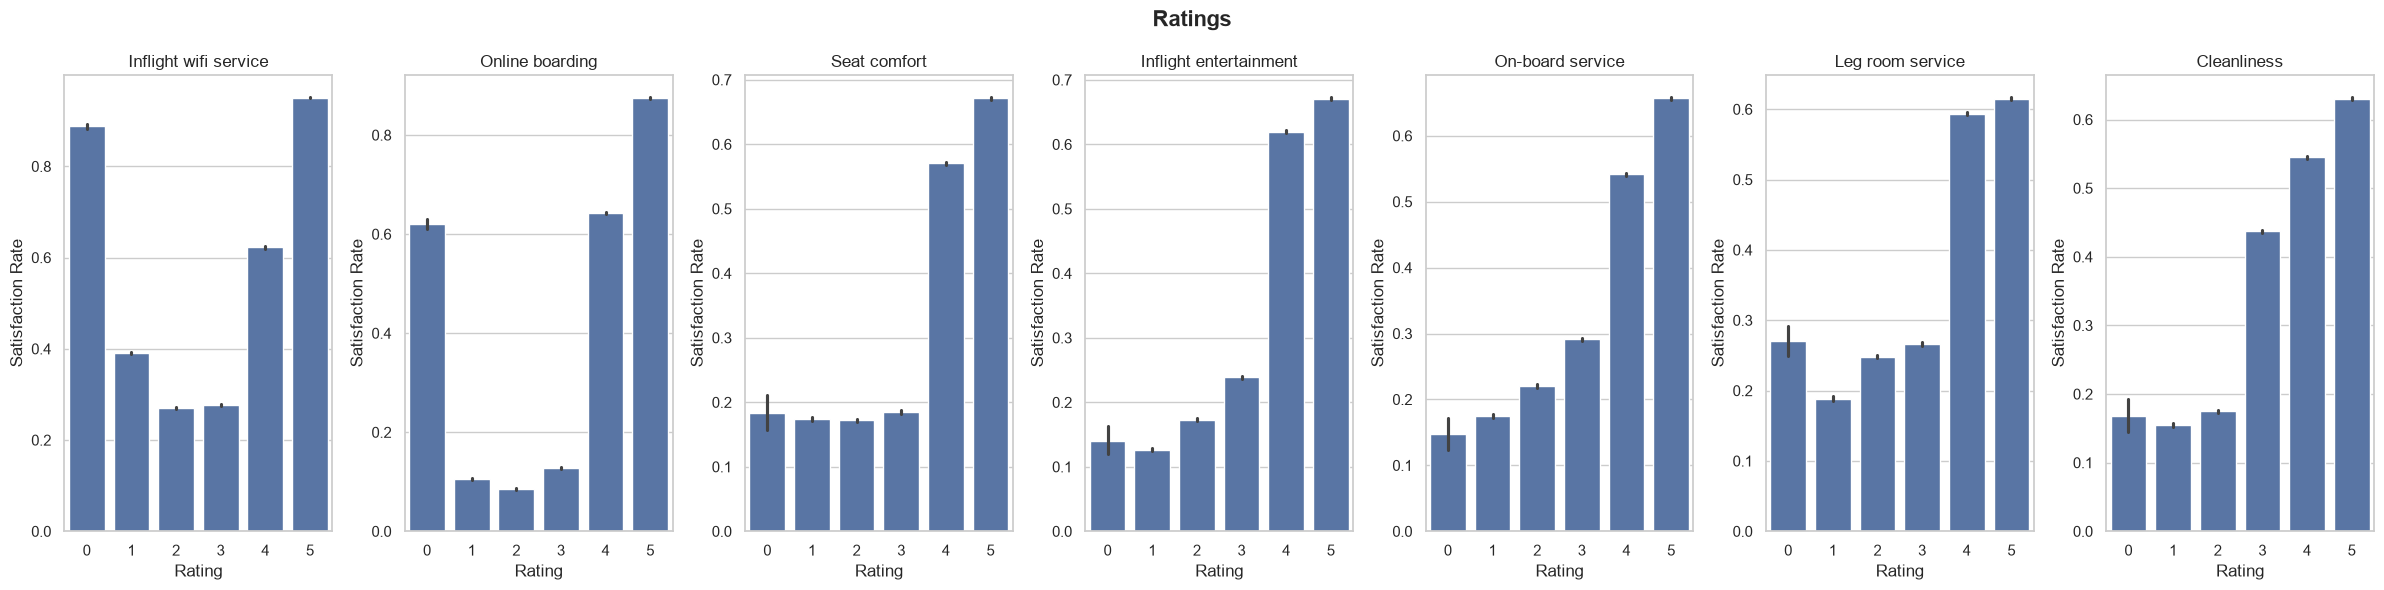

In [22]:
fig, axes = plt.subplots(1, 7, figsize=(24, 6))

fig.suptitle(
    "Ratings",
    fontsize=16,
    fontweight="bold"
)

service_cols = [
    'Inflight wifi service',
    'Online boarding',
    'Seat comfort',
    'Inflight entertainment',
    'On-board service',
    'Leg room service',
    'Cleanliness'
]

for i, col in enumerate(service_cols):

    sns.barplot(
        data=train_df,
        x=col,
        y='satisfaction',
        ax=axes[i]
    )

    axes[i].set_title(col)
    axes[i].set_xlabel("Rating")
    axes[i].set_ylabel("Satisfaction Rate")

plt.tight_layout()
plt.show()

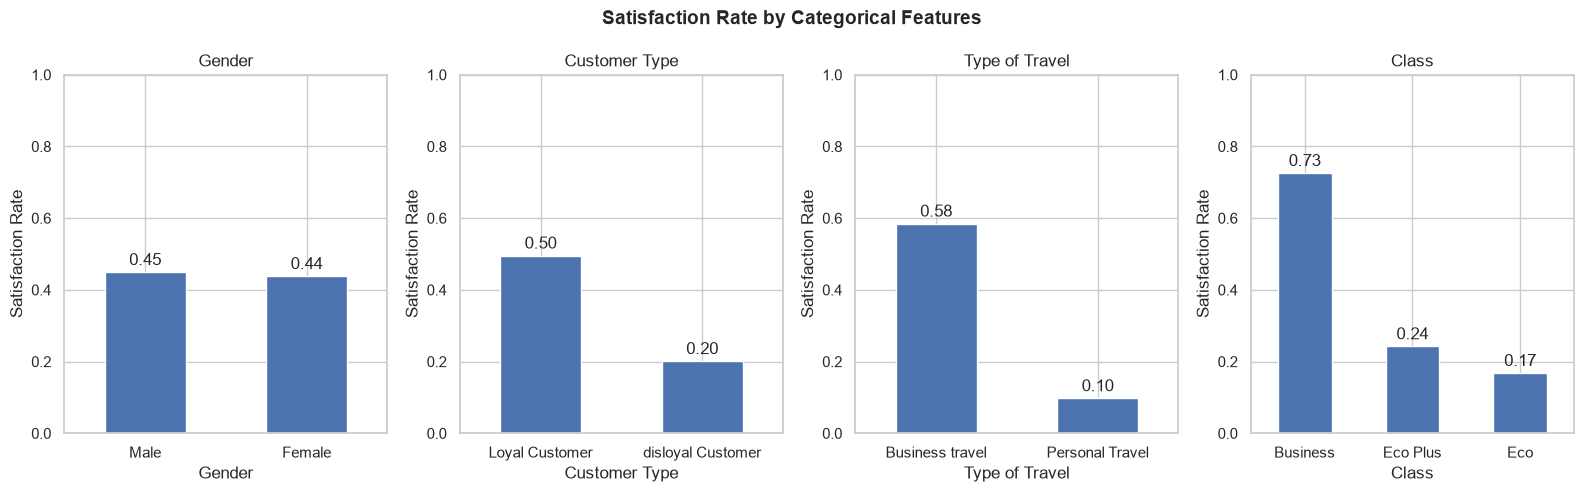

In [54]:
fig, axes = plt.subplots(1, 4, figsize=(16, 5))
cols = ["Gender", "Customer Type", "Type of Travel", "Class"]
fig.suptitle("Satisfaction Rate by Categorical Features", fontsize=14, fontweight="bold")

for ax, col in zip(axes, cols):
    rate = train_df.groupby(col)["satisfaction"].mean().sort_values(ascending=False)
    rate.plot(kind="bar", ax=ax)
    ax.set_title(col)
    ax.set_ylabel("Satisfaction Rate")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
    ax.set_ylim(0, 1)
    for i, v in enumerate(rate.values):
        ax.text(i, v + 0.02, f"{v:.2f}", ha="center", fontsize=12)

plt.tight_layout()
plt.show()

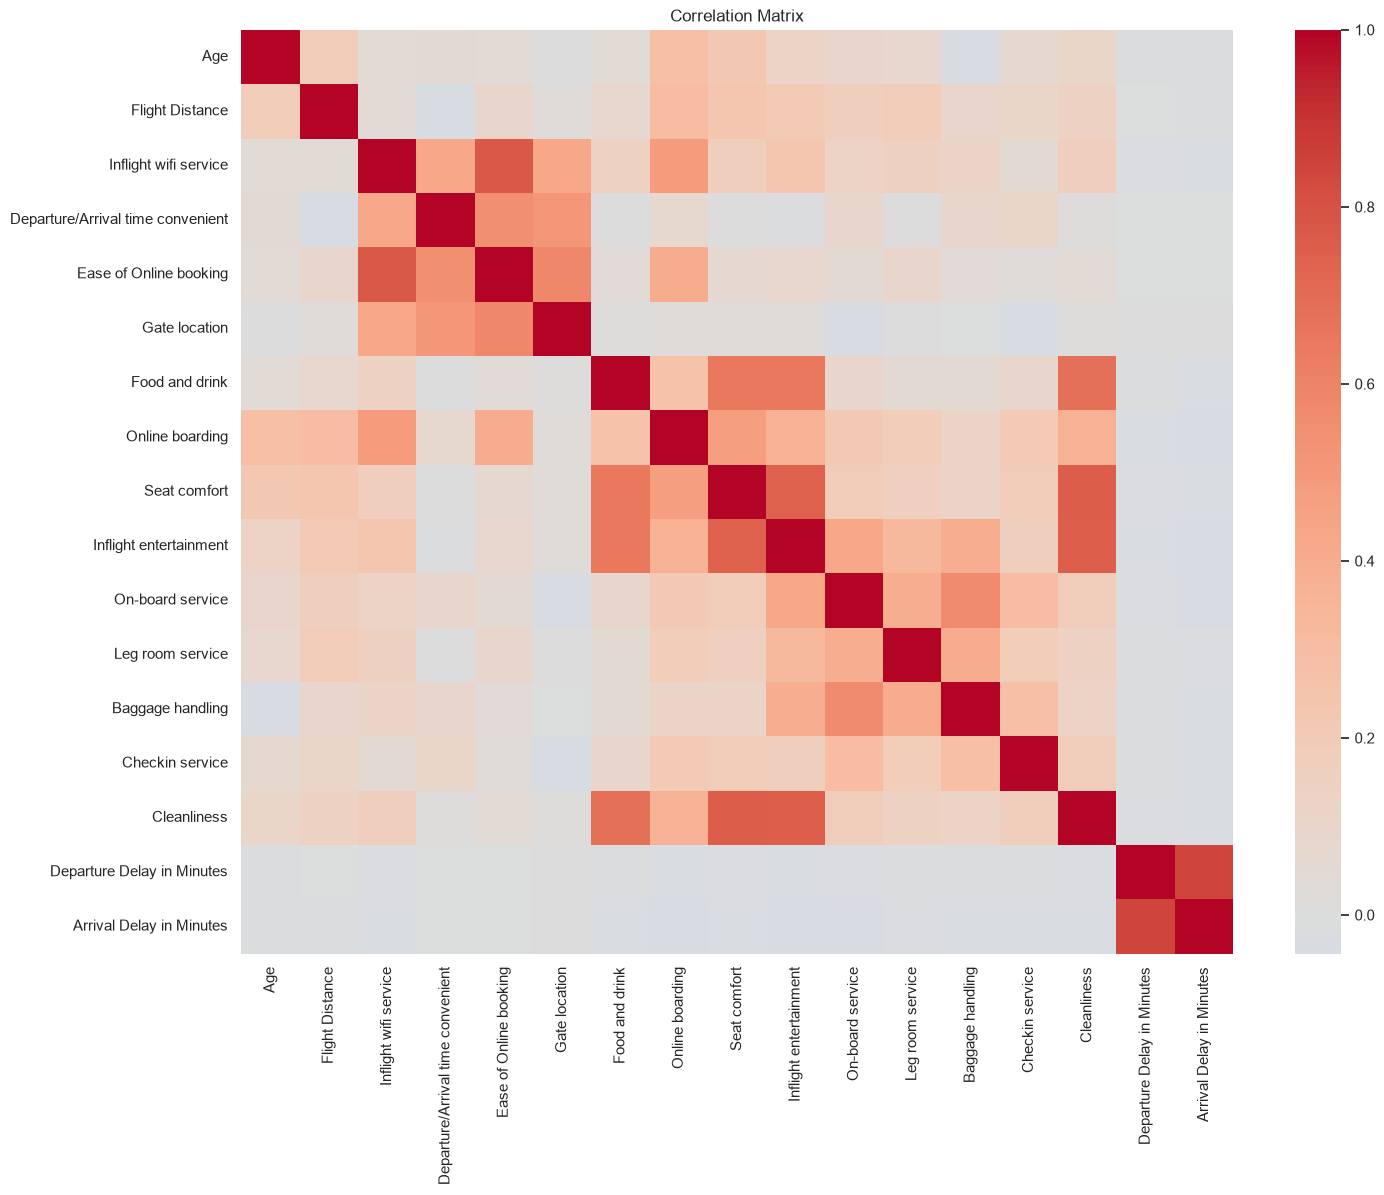

In [43]:
corr = (
    train_df
    .drop(columns='id')
    .select_dtypes(include=np.number)
    .corr()
)

plt.figure(figsize=(16, 12))

sns.heatmap(
    corr,
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Matrix')
plt.show()


In [55]:
categorical_cols = train_df.select_dtypes(include=['object', 'category']).columns

for col in categorical_cols:
    print(col)
    print(train_df[col].value_counts())

Gender
Gender
Male      351683
Female    347952
Name: count, dtype: int64
Customer Type
Customer Type
Loyal Customer       576990
disloyal Customer    122645
Name: count, dtype: int64
Type of Travel
Type of Travel
Business travel    497441
Personal Travel    202194
Name: count, dtype: int64
Class
Class
Business    342212
Eco         327404
Eco Plus     30019
Name: count, dtype: int64


/var/folders/wk/q0mts90d38gch7vsc6z9ccwm0000gn/T/ipykernel_32724/3008951864.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = train_df.select_dtypes(include=['object', 'category']).columns


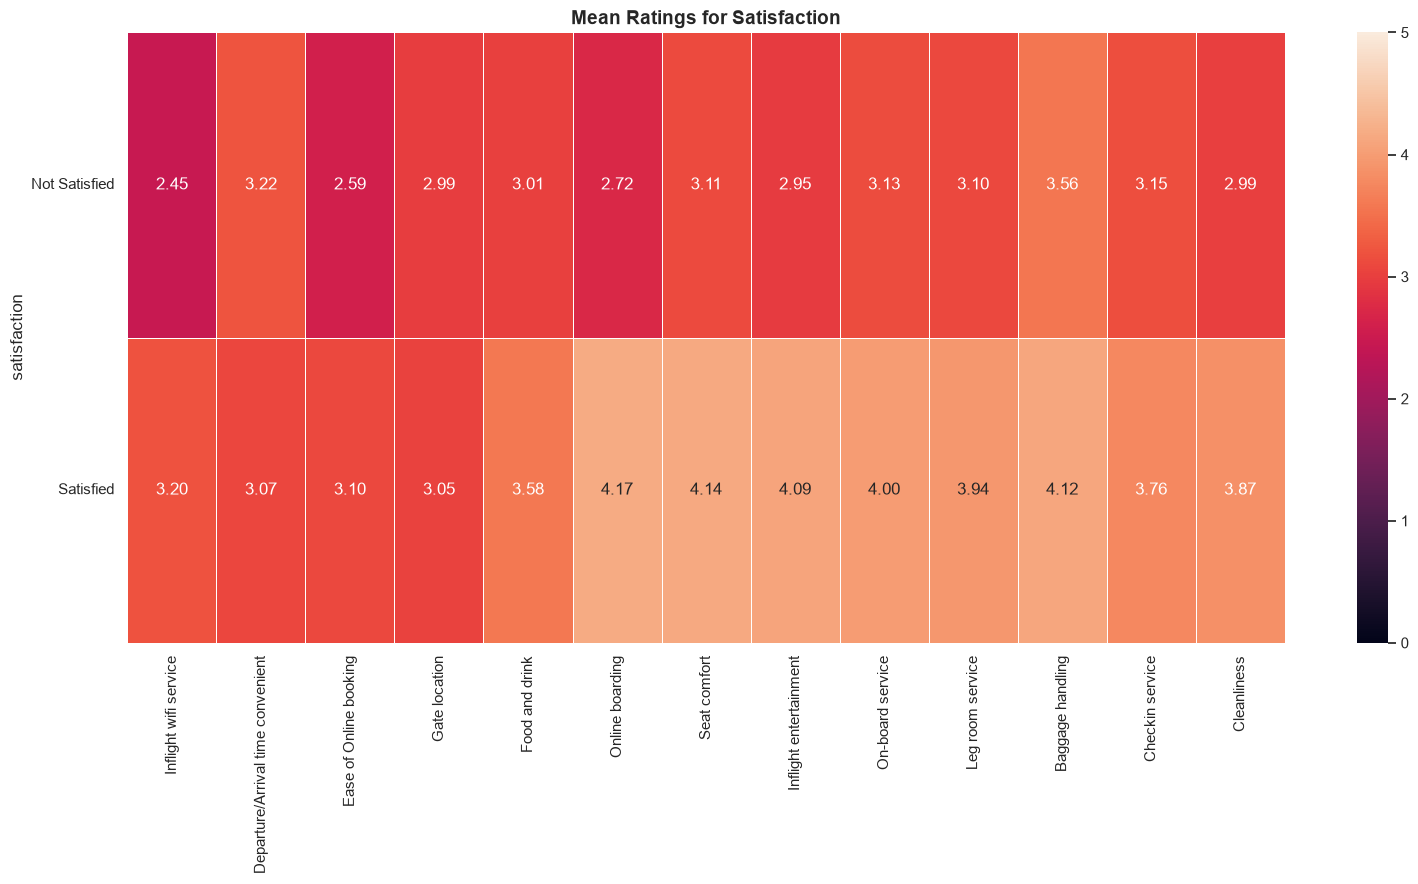

In [56]:
cols = ["Inflight wifi service", "Departure/Arrival time convenient", "Ease of Online booking", "Gate location", "Food and drink", "Online boarding", 
               "Seat comfort", "Inflight entertainment", "On-board service", "Leg room service", "Baggage handling", "Checkin service", "Cleanliness"]
means = train_df.groupby("satisfaction")[cols].mean()

plt.figure(figsize=(16, 9))
sns.heatmap(means, annot=True, fmt=".2f", vmin=0, vmax=5, linewidths=0.5)
plt.title("Mean Ratings for Satisfaction", fontsize=14, fontweight="bold")
plt.yticks([0.5, 1.5], ["Not Satisfied", "Satisfied"], rotation=0)
plt.tight_layout()
plt.show()

In [38]:
train_df['satisfaction'].value_counts(normalize=True) * 100

satisfaction
False    55.642728
True     44.357272
Name: proportion, dtype: float64

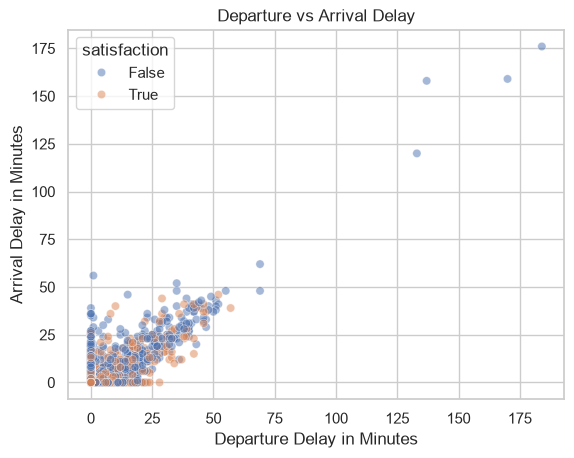

In [52]:
sns.scatterplot(
    data=train_df.sample(10000, random_state=42),
    x='Departure Delay in Minutes',
    y='Arrival Delay in Minutes',
    hue='satisfaction',
    alpha=0.5
)

plt.title('Departure vs Arrival Delay')
plt.show()